# 🌌 EPB Detection System — Application, Explainability & Temporal Analysis (V4)

This notebook loads the trained **V4.0 Two-Stage Cascaded EPB Detection System** and generates:
1. **2DPCA Reconstruction Error Maps** (`recon_error_without.png`, `recon_error_with.png`)
2. **SHAP Pixel-Space Attribution Maps** (`shap_analysis_without.png`, `shap_analysis_with.png`)
3. **Nocturnal Temporal Sequence Monitoring (Light Theme for Print Legibility)** (`temporal_without_epb.png`, `temporal_with_epb.png`)
4. **Two-Stage Cascaded Cloud Quality Control (Stage 1 + Stage 2)** on the overcast night of 2026-06-24/25 at CA (folder `util/CA_20260624`, frames dated `20260625` in UTC) (`temporal_cloudy_qc.png`)

Folder names under `util/` use the **night start date**; frame filenames use the **UTC date** of each frame, so a night that crosses 00:00 UT contains files from the next calendar day.


In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from epb_detection_system_v2 import (
    load_epb_dataset, augment_epb_data,
    load_model, preprocess_epb_image,
    explain_feature_importance, explain_feature_importance_2, explain_feature_importance_3,
    explain_shap_importance,
    analyze_temporal_sequence, analyze_temporal_sequence_with_qc,
    predict_with_qc, assess_sky_quality
)

FIGS_DIR = "../waimlap2026/epb/figs"
os.makedirs(FIGS_DIR, exist_ok=True)

# Load V4.0 trained model
model_data = load_model("models/epb_recognition_model-v4.0.pkl")
loaded_system = model_data.system
TARGET_SIZE = model_data.target_size

# Load reference training set for SHAP background
X_all, y_all, _ = load_epb_dataset(
    data_folder="data/all-images",
    label_file="data/epb_labels.csv",
    target_size=TARGET_SIZE,
    apply_preprocessing=True
)
print(f"Loaded model v{model_data.version} | Reference dataset: {X_all.shape}")


Loaded model v4.0 | Reference dataset: (572, 64, 64)


No-EPB Sample (img-teste/O6_BJL_20250723_003008.png) -> Sky QC: DEGRADED (Partially Clear / Degraded Visibility (Stars: 6405, Mean brightness: 77.3))
   • Status: Céu Quieto (Visibilidade Parcial) | EPB Probability: 0.42%


💾 Figure saved: ../waimlap2026/epb/figs/recon_error_without.png (300 DPI)


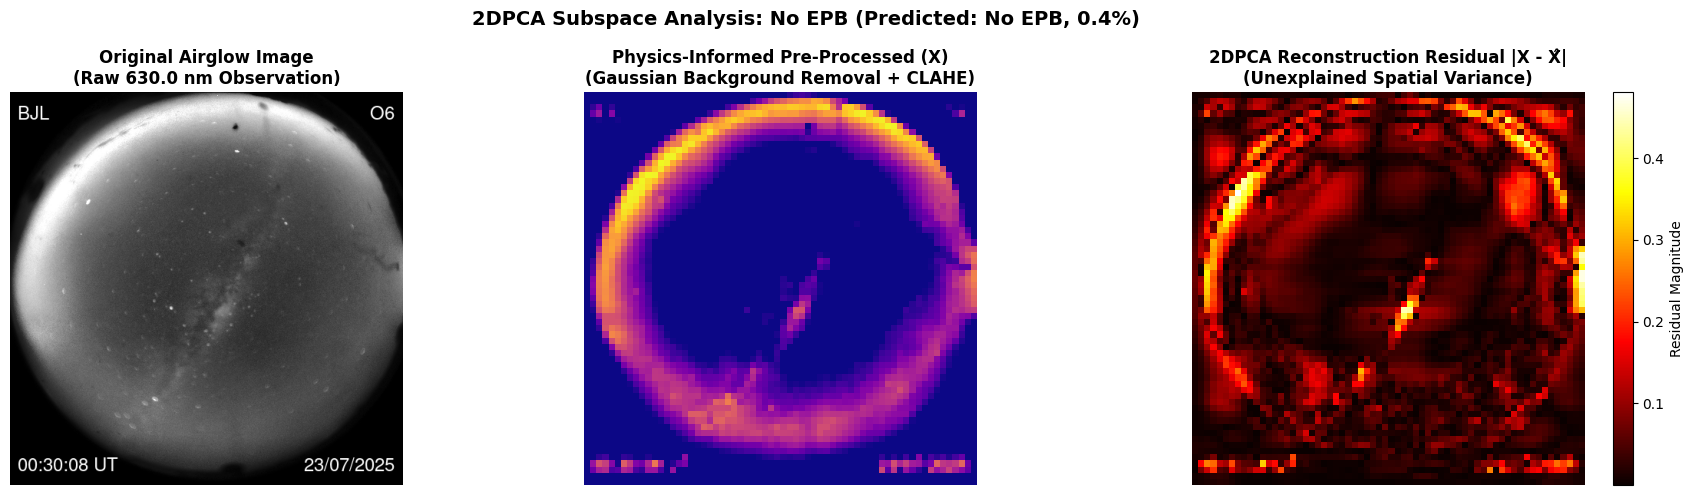

/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
TreeExplainer falhou com xgboost, tentando próximo modelo...



🔬 SHAP EXPLAINABILITY ANALYSIS — Supervised Pixel Attribution

📸 Image: O6_BJL_20250723_003008.png
   • True class: No EPB
   • Prediction: No EPB (0.4%)
   • SHAP Method: TreeExplainer (XGBoost + RF)

📊 SHAP contribution by quadrant:
   • Upper Left: 32.7% (↓ No EPB)
   • Upper Right: 25.7% (↓ No EPB)
   • Lower Left: 21.5% (↓ No EPB)
   • Lower Right: 20.2% (↑ EPB)

📐 Spearman Correlation (|SHAP| vs. 2DPCA Reconstruction Error): 0.211


💾 High-resolution SHAP map saved: ../waimlap2026/epb/figs/shap_analysis_without.png (300 DPI)


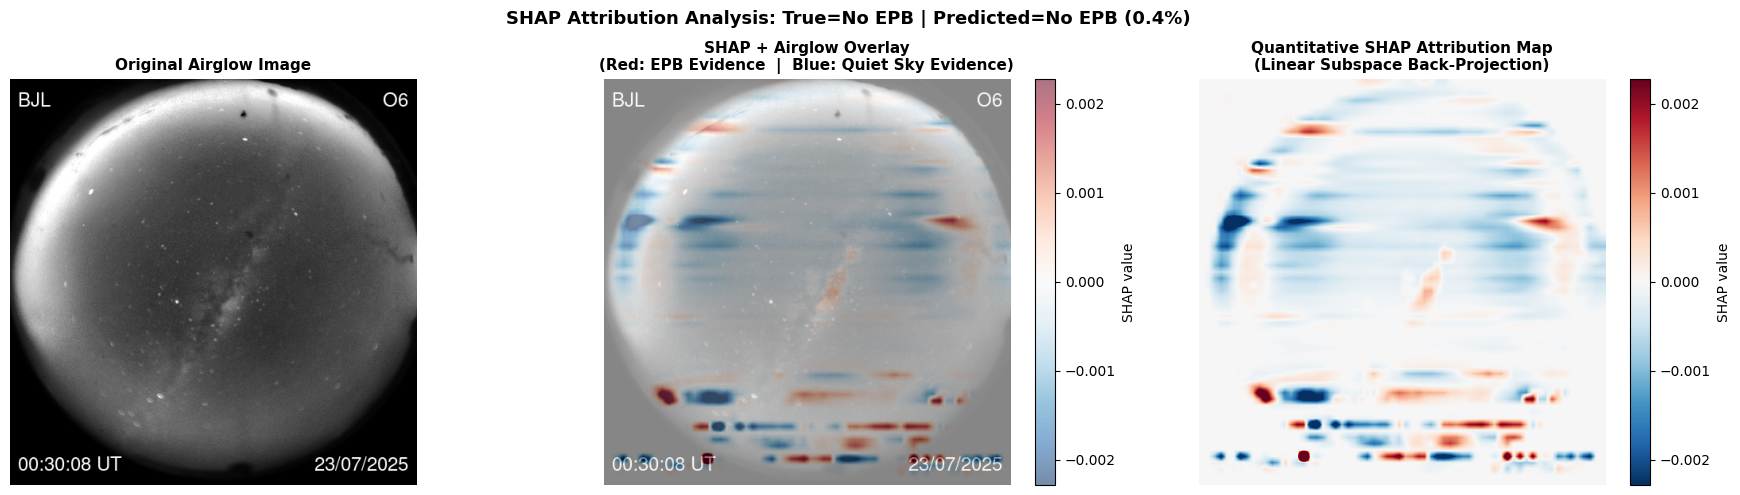

In [2]:
# ========== CASE 1: QUIET IONOSPHERE (NO EPB) — CASCADED QC, RECONSTRUCTION & SHAP ==========
img_path_no_epb = "img-teste/O6_BJL_20250723_003008.png"
raw_no_epb = cv2.imread(img_path_no_epb, cv2.IMREAD_GRAYSCALE)
qc_no_epb = predict_with_qc(loaded_system, raw_no_epb, target_size=TARGET_SIZE)
proc_no_epb = preprocess_epb_image(raw_no_epb, target_size=TARGET_SIZE)

print(f"No-EPB Sample ({img_path_no_epb}) -> Sky QC: {qc_no_epb.qc.condition} ({qc_no_epb.qc.reason})")
print(f"   • Status: {qc_no_epb.status_label} | EPB Probability: {qc_no_epb.prob_epb*100:.2f}%")

explain_feature_importance_3(
    loaded_system, proc_no_epb, y_sample=0,
    filename="O6_BJL_20250723_003008.png",
    image_folder="img-teste",
    save_path=f"{FIGS_DIR}/recon_error_without.png",
    dpi=300,
    show_filename=False
)

shap_no_epb = explain_shap_importance(
    loaded_system, proc_no_epb, y_sample=0,
    X_background=X_all,
    filename="O6_BJL_20250723_003008.png",
    image_folder="img-teste",
    save_path=f"{FIGS_DIR}/shap_analysis_without.png",
    dpi=300,
    show_filename=False
)


EPB Sample (img-teste/O6_CA_20251023_001620.png) -> Sky QC: CLEAR (Clear Sky with High Visibility (Stars: 6942, Mean brightness: 96.1))
   • Status: Bolha de Plasma (EPB) Detectada | EPB Probability: 99.17%


💾 Figure saved: ../waimlap2026/epb/figs/recon_error_with.png (300 DPI)


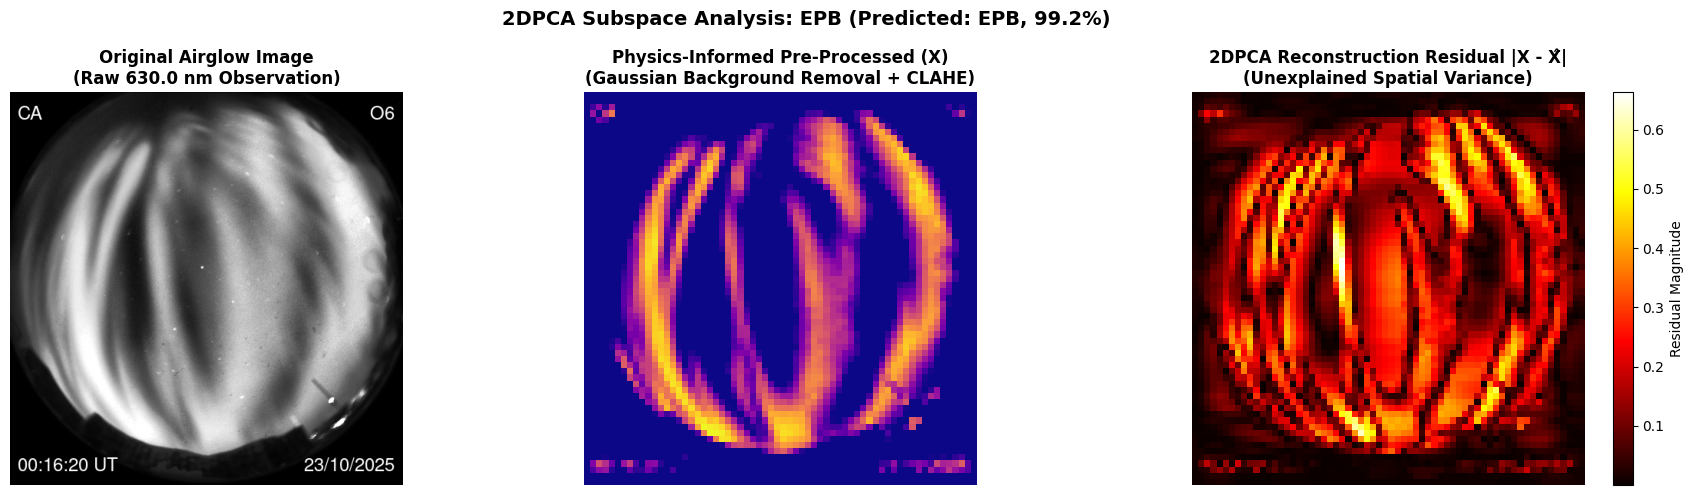

TreeExplainer falhou com xgboost, tentando próximo modelo...



🔬 SHAP EXPLAINABILITY ANALYSIS — Supervised Pixel Attribution

📸 Image: O6_CA_20251023_001620.png
   • True class: EPB
   • Prediction: EPB (99.2%)
   • SHAP Method: TreeExplainer (XGBoost + RF)

📊 SHAP contribution by quadrant:
   • Lower Right: 31.3% (↑ EPB)
   • Lower Left: 25.4% (↓ No EPB)
   • Upper Left: 22.8% (↑ EPB)
   • Upper Right: 20.5% (↑ EPB)

📐 Spearman Correlation (|SHAP| vs. 2DPCA Reconstruction Error): 0.559


💾 High-resolution SHAP map saved: ../waimlap2026/epb/figs/shap_analysis_with.png (300 DPI)


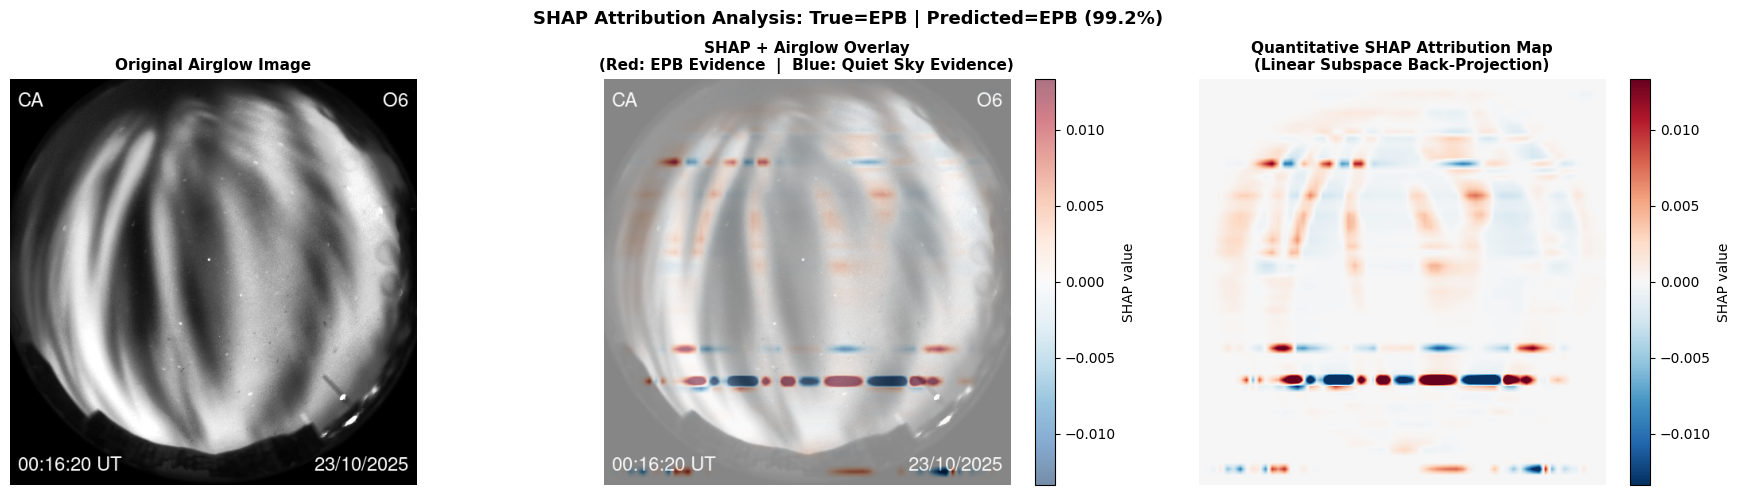

In [3]:
# ========== CASE 2: ACTIVE EPB EVENT — CASCADED QC, RECONSTRUCTION & SHAP ==========
img_path_epb = "img-teste/O6_CA_20251023_001620.png"
raw_epb = cv2.imread(img_path_epb, cv2.IMREAD_GRAYSCALE)
qc_epb = predict_with_qc(loaded_system, raw_epb, target_size=TARGET_SIZE)
proc_epb = preprocess_epb_image(raw_epb, target_size=TARGET_SIZE)

print(f"EPB Sample ({img_path_epb}) -> Sky QC: {qc_epb.qc.condition} ({qc_epb.qc.reason})")
print(f"   • Status: {qc_epb.status_label} | EPB Probability: {qc_epb.prob_epb*100:.2f}%")

explain_feature_importance_3(
    loaded_system, proc_epb, y_sample=1,
    filename="O6_CA_20251023_001620.png",
    image_folder="img-teste",
    save_path=f"{FIGS_DIR}/recon_error_with.png",
    dpi=300,
    show_filename=False
)

shap_epb = explain_shap_importance(
    loaded_system, proc_epb, y_sample=1,
    X_background=X_all,
    filename="O6_CA_20251023_001620.png",
    image_folder="img-teste",
    save_path=f"{FIGS_DIR}/shap_analysis_with.png",
    dpi=300,
    show_filename=False
)


🕐 TEMPORAL SEQUENCE ANALYSIS OF IMAGES (Cascaded QC + 2DPCA)
📂 Folder: util/BJL_20250722/processed
📸 Total images: 230
🛡️  Sky Quality Control (QC): Disabled



📊 Prediction summary:
   • Clear Sky with EPB:    0 images (0.0%)
   • Clear Sky without EPB: 230 images (100.0%)
   • Average EPB probability (Clear Sky): 0.4%


💾 High-resolution timeline saved: ../waimlap2026/epb/figs/temporal_without_epb.png (300 DPI)


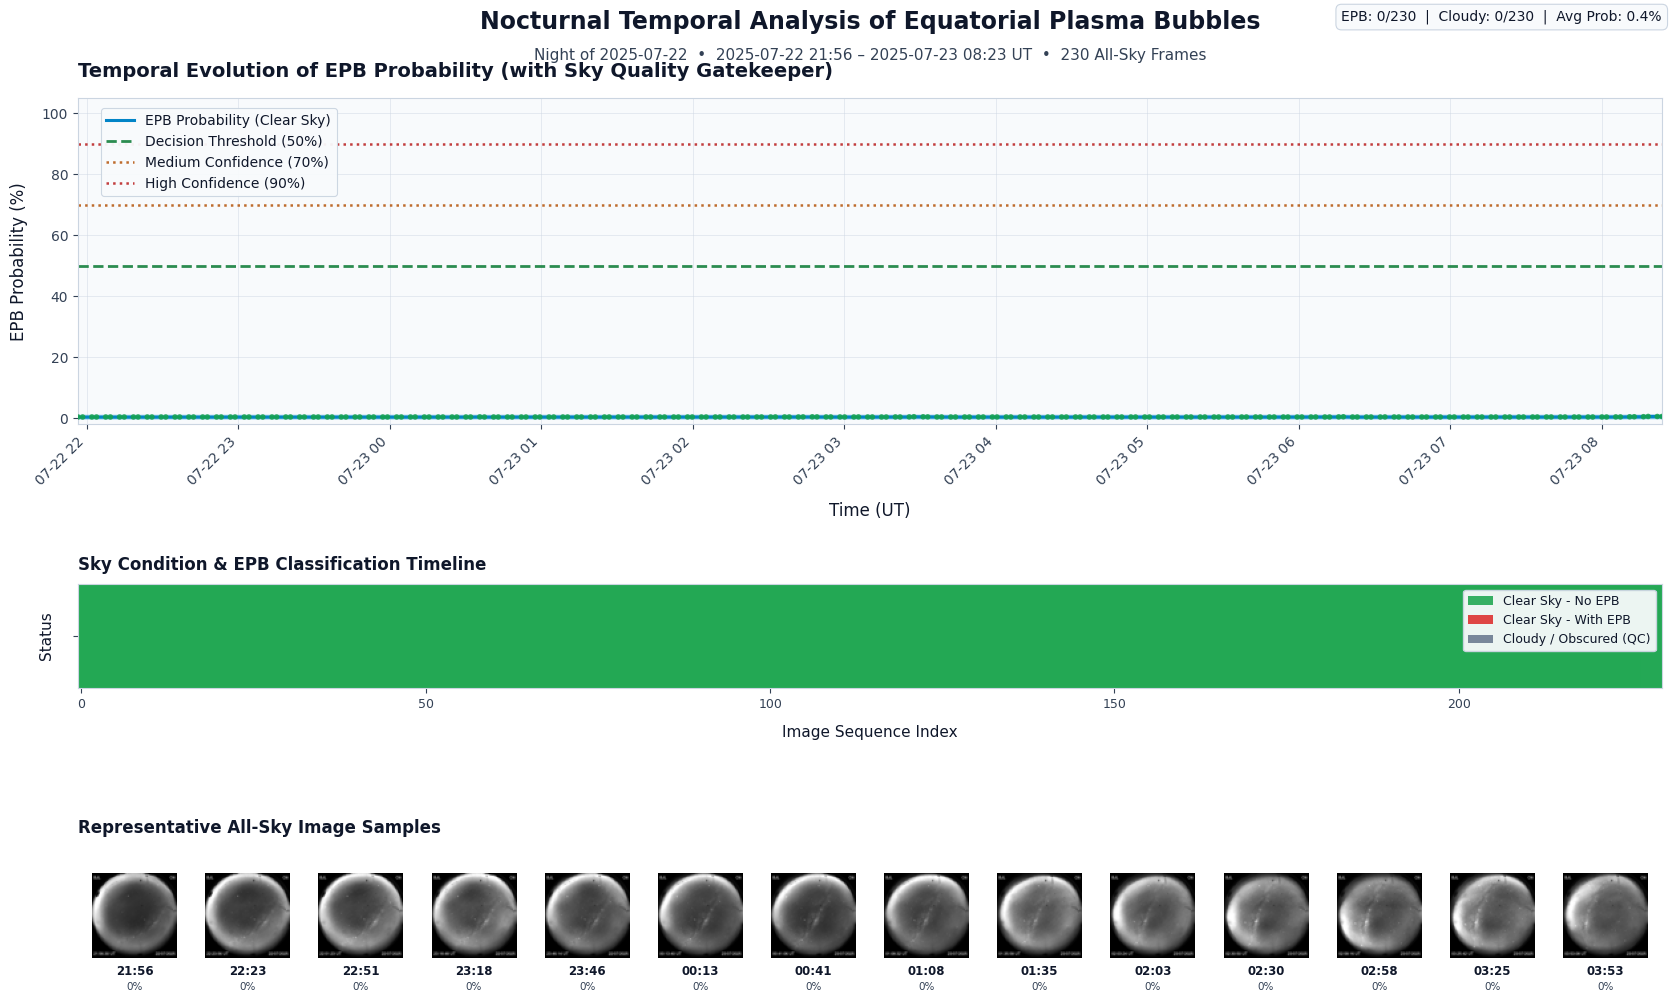


✅ TEMPORAL ANALYSIS COMPLETED


In [4]:
# ========== TEMPORAL SEQUENCE 1: QUIET NIGHT (BJL, night of 2025-07-22/23, n=230 frames) ==========
df_quiet = analyze_temporal_sequence(
    system=loaded_system,
    image_folder="util/BJL_20250722/processed",
    target_size=TARGET_SIZE,
    show_thumbnails=True,
    thumbnail_interval=10,
    use_qc=False,
    theme="light",
    save_path=f"{FIGS_DIR}/temporal_without_epb.png",
    dpi=300
)


🕐 TEMPORAL SEQUENCE ANALYSIS OF IMAGES (Cascaded QC + 2DPCA)
📂 Folder: util/CA_20251022/processed
📸 Total images: 140
🛡️  Sky Quality Control (QC): Disabled



📊 Prediction summary:
   • Clear Sky with EPB:    138 images (98.6%)
   • Clear Sky without EPB: 2 images (1.4%)
   • Average EPB probability (Clear Sky): 92.0%

🔄 Detected transitions (2):
   • 21:18:24 - Changed to: EPB (63.8%)
   • 07:08:21 - Changed to: No EPB (2.1%)


💾 High-resolution timeline saved: ../waimlap2026/epb/figs/temporal_with_epb.png (300 DPI)


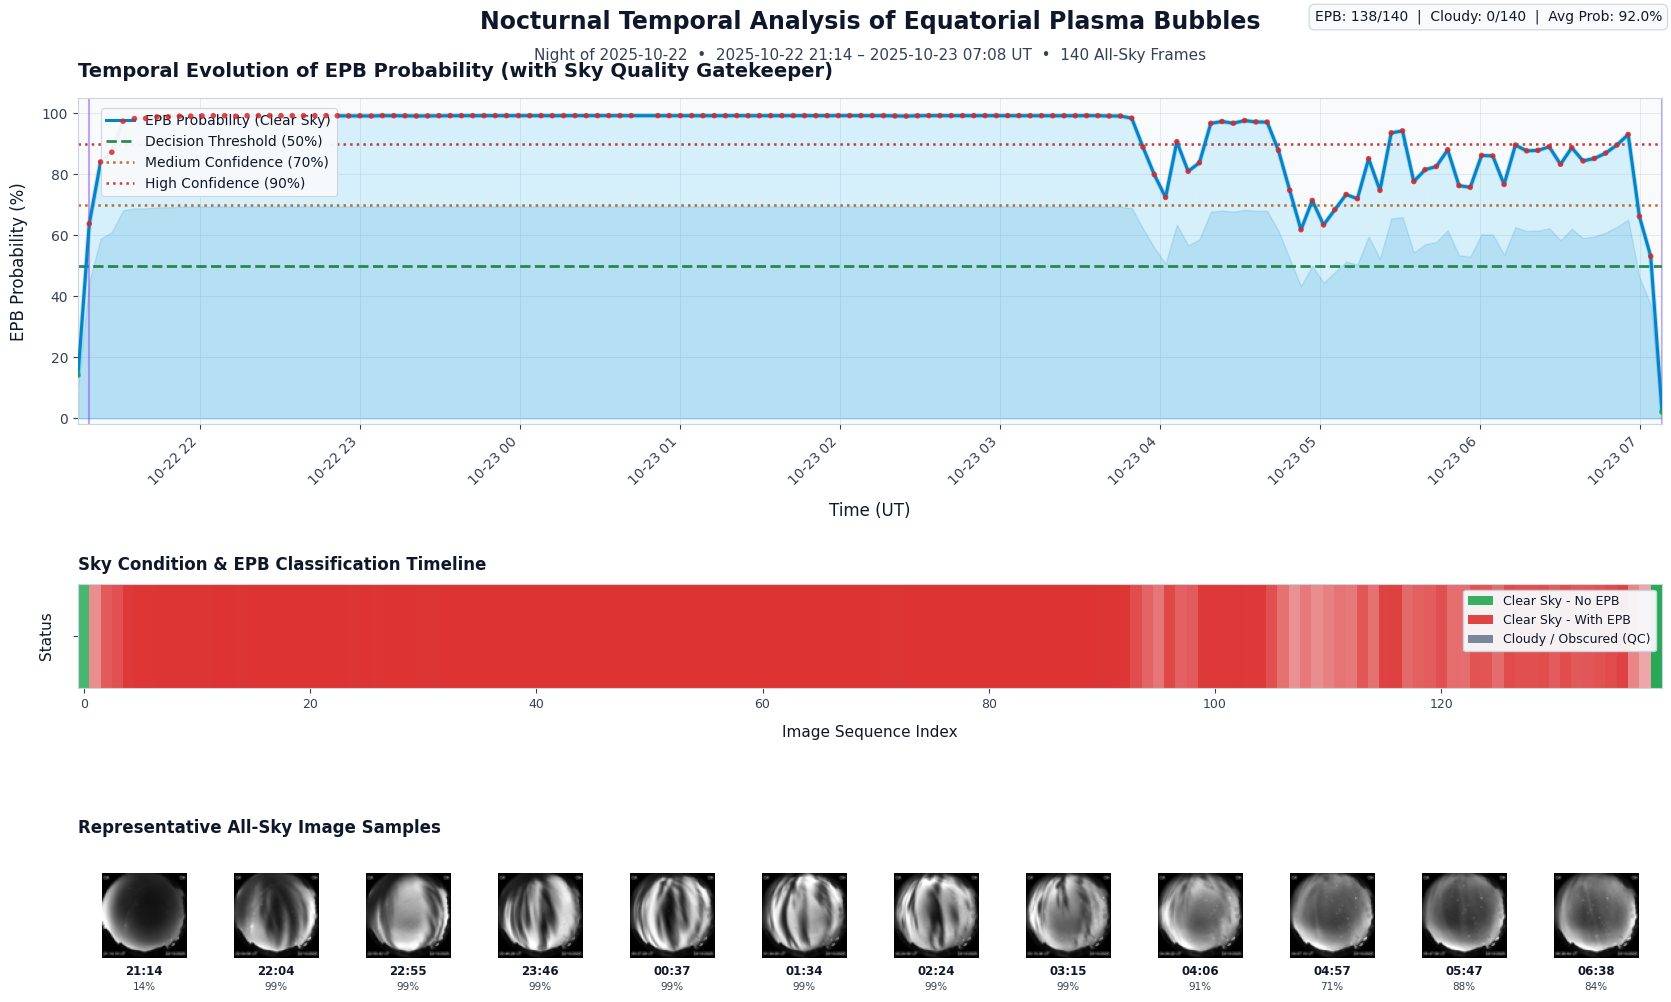


✅ TEMPORAL ANALYSIS COMPLETED


In [5]:
# ========== TEMPORAL SEQUENCE 2: ACTIVE EPB NIGHT (CA, night of 2025-10-22/23, n=140 frames) ==========
df_active = analyze_temporal_sequence(
    system=loaded_system,
    image_folder="util/CA_20251022/processed",
    target_size=TARGET_SIZE,
    show_thumbnails=True,
    thumbnail_interval=12,
    use_qc=False,
    theme="light",
    save_path=f"{FIGS_DIR}/temporal_with_epb.png",
    dpi=300
)


🕐 TEMPORAL SEQUENCE ANALYSIS OF IMAGES (Cascaded QC + 2DPCA)
📂 Folder: util/CA_20260624/processed
📸 Total images: 62
🛡️  Sky Quality Control (QC): Enabled



📊 Prediction summary:
   • Clear Sky with EPB:    1 images (1.6%)
   • Clear Sky without EPB: 12 images (19.4%)
   • Cloudy / Obscured Sky: 49 images (79.0%)
   • Average EPB probability (Clear Sky): 9.1%

🔄 Detected transitions (14):
   • 04:40:39 - Changed to: No EPB (2.9%)
   • 04:57:36 - Changed to: Cloudy Sky (QC) (0.0%)
   • 05:56:50 - Changed to: EPB (93.3%)
   • 06:01:06 - Changed to: Cloudy Sky (QC) (0.0%)
   • 06:05:20 - Changed to: No EPB (7.2%)
   • 06:22:15 - Changed to: Cloudy Sky (QC) (0.0%)
   • 06:39:10 - Changed to: No EPB (1.2%)
   • 06:43:24 - Changed to: Cloudy Sky (QC) (0.0%)
   • 07:13:01 - Changed to: No EPB (0.7%)
   • 07:17:15 - Changed to: Cloudy Sky (QC) (0.0%)
   • 07:25:42 - Changed to: No EPB (0.7%)
   • 07:29:56 - Changed to: Cloudy Sky (QC) (0.0%)
   • 07:38:24 - Changed to: No EPB (4.1%)
   • 07:42:38 - Changed to: Cloudy Sky (QC) (0.0%)


💾 High-resolution timeline saved: ../waimlap2026/epb/figs/temporal_cloudy_qc.png (300 DPI)


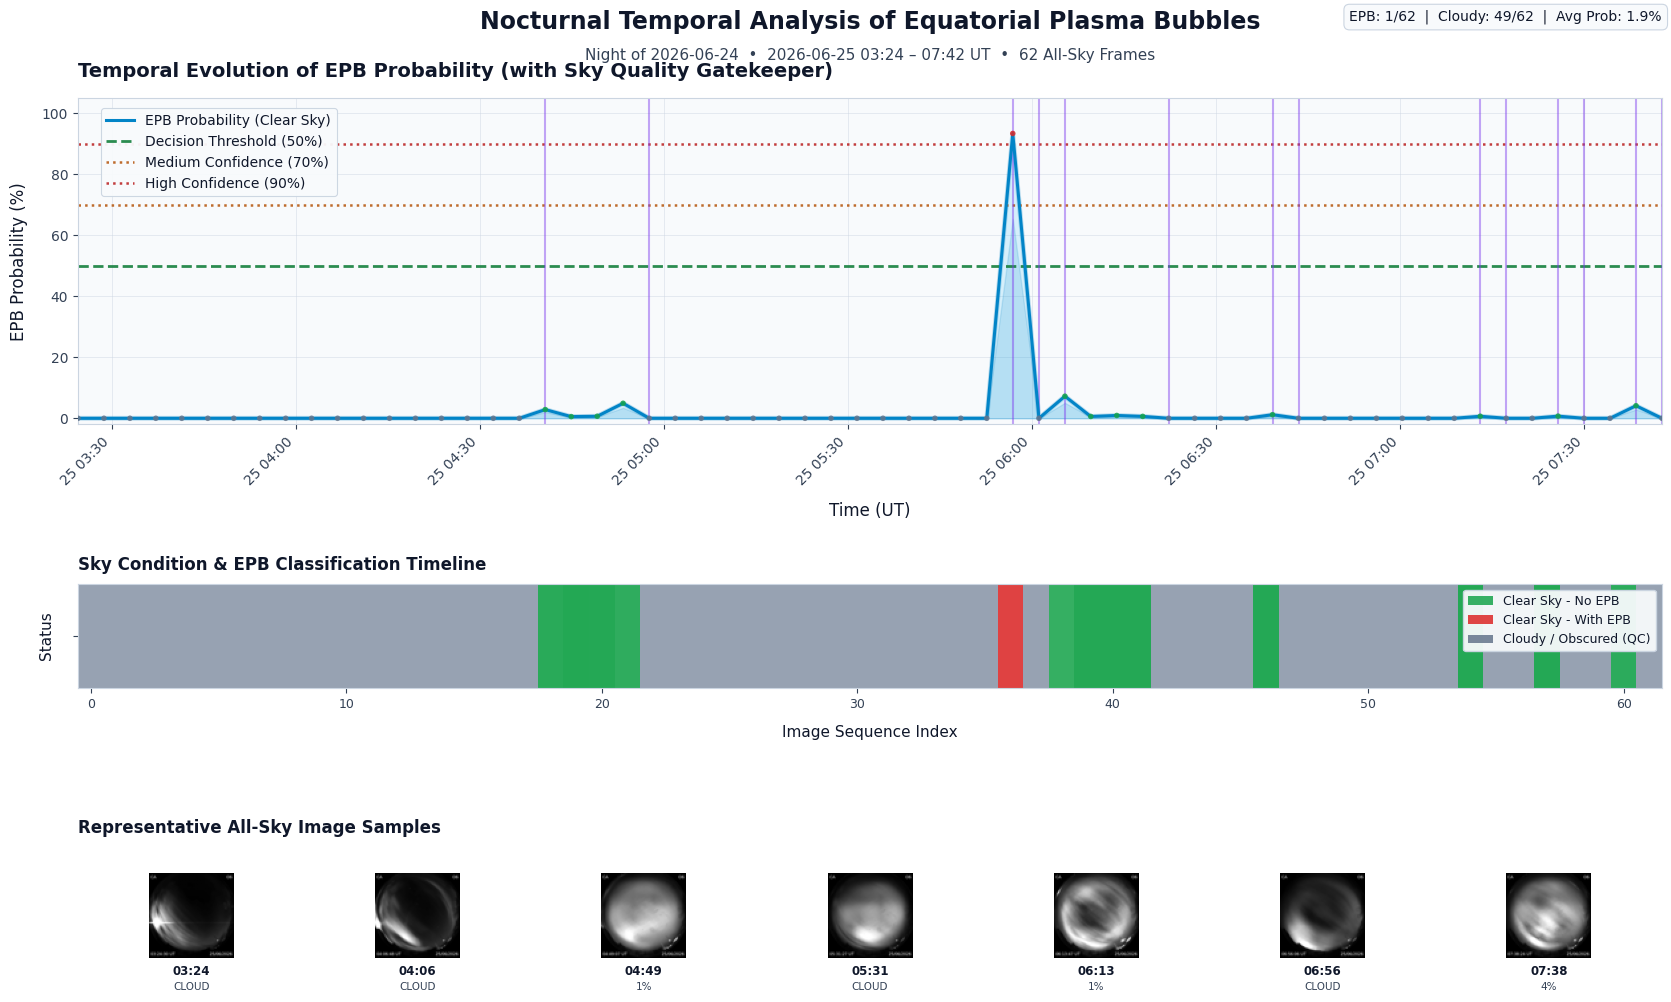


✅ TEMPORAL ANALYSIS COMPLETED


In [6]:
# ========== TEMPORAL SEQUENCE 3: CLOUDY NIGHT WITH STAGE 1 QC (CA, night of 2026-06-24/25, n=62 frames) ==========
# Folder is named by the night start date; frame filenames carry the UTC date (O6_CA_20260625_04xx..07xx UT).
df_cloudy_qc = analyze_temporal_sequence_with_qc(
    system=loaded_system,
    image_folder="util/CA_20260624/processed",
    target_size=TARGET_SIZE,
    show_thumbnails=True,
    thumbnail_interval=10,
    threshold_stars=4500,
    theme="light",
    save_path=f"{FIGS_DIR}/temporal_cloudy_qc.png",
    dpi=300
)
